<a href="https://colab.research.google.com/github/JhonWV/Ciencias_Datos/blob/main/Actividad5Preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Jhon Wilfer Virguez Sierra
*   MATRÍCULA: A01841719

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [161]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [162]:
import os
DIR = "/content/drive/MyDrive/TEC/Ciencia de datos"
os.chdir(DIR)

In [163]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer
from pandas.api.types import CategoricalDtype
from scipy import stats

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [164]:
#Descarga el archivo: heart_disease.csv y guarda, en un dataframe (cardio_df), todos sus registros
cardio_df = pd.read_csv('/content/drive/MyDrive/TEC/Ciencia de datos/heart_disease.csv')
cardio_df

,id,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
914,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
915,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
916,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


In [165]:
#Haz que la columna id sea el índice del dataframe.
cardio_df = cardio_df.set_index("id")
cardio_df

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2


In [166]:
#Utiliza el método info() del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


¿Cuántas columnas son numéricas y cuántas de texto?

De acuerdo con la información de la consulta, siete (7) columnas son numéricas, siendo dos (2) del tipo `int64` (`age` y `num`) y cinco (5) tipo `float64` (`trestbps`, `chol`, `thalch`, `oldpeak`, `ca`). Las demas columnas, ocho (8), son columnas de texto  o categóricas de tipo `object`: `sex`, `origin`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `thal`

In [167]:
# Determinando la cantidad de valores únicos por columna
cardio_df.nunique()

,0
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [168]:
cardio_df['num'].unique()

array([0, 2, 1, 3, 4])

In [169]:
#Definir los tipos categóricos ordinales con su orden correcto
tipo_ca = CategoricalDtype(categories=[0.0, 1.0, 2.0, 3.0], ordered=True)
tipo_num = CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True)

# Realizar la conversión en el DataFrame
cardio_df['ca'] = cardio_df['ca'].astype(tipo_ca)
cardio_df['num'] =cardio_df['num'].astype(tipo_num)

cardio_df[['ca', 'num']].dtypes

,0
ca,category
num,category


3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [170]:
# Estadísticas descriptivas de las variables numéricas, incluyendo asimetria y curtosis
variables_numericas = cardio_df.select_dtypes(include=['number'])
est_descritiva=cardio_df.describe().T
est_descritiva['simetria'] = variables_numericas.skew()
est_descritiva['curtosis'] = variables_numericas.kurt()
est_descritiva

,count,mean,std,min,25%,50%,75%,max,simetria,curtosis
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834


In [171]:
#Estadísticas descriptivas variables categóricas, imprime además las tablas de frecuencia.
df_categoricas = cardio_df.select_dtypes(include=['object','category']).describe().T
df_categoricas

,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309.0,4.0,0.0,181.0
thal,434,3,normal,196
num,918,5,0,411


In [172]:
#Estadísticas descriptivas variables categóricas, imprime además las tablas de frecuencia.
#se toma de base la tabla con el describe().T
df_categoricas = cardio_df.select_dtypes(include=['object', 'category']).describe().T

#  se añade  el porcentaje que representa la moda (top) sobre los datos validos
df_categoricas['% moda/total_validos'] = (df_categoricas['freq'] / df_categoricas['count'] * 100).round(2)

# se calcula y agrega las frecuencias completas por cada categoría (conteo y %)
def obtener_distribucion(col):
    counts = cardio_df[col].value_counts(dropna=False)
    percents = (cardio_df[col].value_counts(normalize=True, dropna=False) * 100).round(1)
    # formatear como: "Categoría: Conteo (Porcentaje%)"
    return ", ".join([f"{k}: {v} ({percents[k]}%)" for k, v in counts.items()])

df_categoricas['Detalle de frecuencias'] = [obtener_distribucion(col) for col in df_categoricas.index]

# tabla final ensamblada
df_categoricas

,count,unique,top,freq,% moda/total_validos,Detalle de frecuencias
sex,918,2,Male,724,78.867102,"Male: 724 (78.9%), Female: 194 (21.1%)"
origin,918,4,Cleveland,304,33.115468,"Cleveland: 304 (33.1%), Hungary: 292 (31.8%), ..."
cp,918,4,asymptomatic,495,53.921569,"asymptomatic: 495 (53.9%), non-anginal: 204 (2..."
fbs,829,2,False,691,83.353438,"False: 691 (75.3%), True: 138 (15.0%), nan: 89..."
restecg,918,3,normal,551,60.021786,"normal: 551 (60.0%), lv hypertrophy: 188 (20.5..."
exang,863,2,False,526,60.950174,"False: 526 (57.3%), True: 337 (36.7%), nan: 55..."
slope,610,3,flat,345,56.557377,"flat: 345 (37.6%), nan: 308 (33.6%), upsloping..."
ca,309.0,4.0,0.0,181.0,58.576052,"nan: 609 (66.3%), 0.0: 181 (19.7%), 1.0: 67 (7..."
thal,434,3,normal,196,45.16129,"nan: 484 (52.7%), normal: 196 (21.4%), reversa..."
num,918,5,0,411,44.771242,"0: 411 (44.8%), 1: 263 (28.6%), 2: 109 (11.9%)..."


4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [173]:
# 1. Calcular el porcentaje de nulos por columna
porcentaje_nulos = (cardio_df.isnull().mean() * 100).round(2)
print(df_nulos)

          Valores Nulos  Porcentaje (%)
ca                  609           66.34
thal                484           52.72
slope               308           33.55
fbs                  89            9.69
oldpeak              62            6.75
trestbps             59            6.43
thalch               55            5.99
exang                55            5.99
chol                 30            3.27
sex                   0            0.00
origin                0            0.00
cp                    0            0.00
age                   0            0.00
restecg               0            0.00
num                   0            0.00


In [174]:
#Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
cardio_df = cardio_df.drop(columns=['slope', 'ca', 'thal'])
cardio_df

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
id,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,0
...,...,...,...,...,...,...,...,...,...,...,...,...
916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,1
917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,0
918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,2


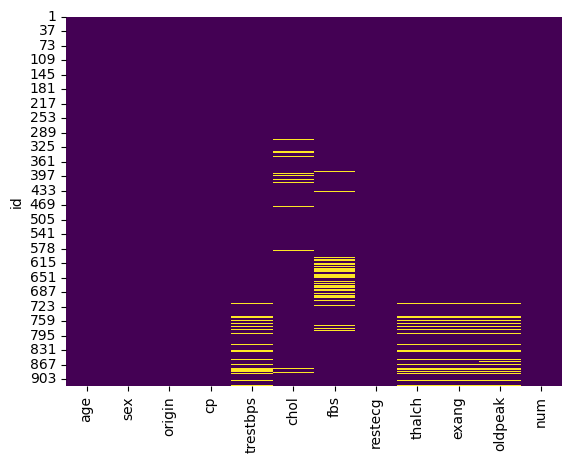

In [175]:
#Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
sns.heatmap(cardio_df.isna(), cbar=False, cmap='viridis')
plt.show()

Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se identifican las filas donde estas variables no presentan valores al mismo tiempo: `trestbps` (Presión arterial en reposo al ingreso al hospital),`thalach`(frecuencia cardíaca máxima alcanzada), `exang` (angina inducida por ejercicio ) y  `oldpeak`(depresión del segmento ST inducida por ejercicio respecto al reposo). Esto podría estar indicando que se trata de algo sistematico, ya que se concentra en las mismas personas. Sobre la ausencia simultánea en Pruebas de Esfuerzo (thalch, exang, oldpeak): se debe a que  las  tres variables se obtienen  como resultado de la aplicacion de una prueba de esfuerzo ergométrica (electrocardiograma de esfuerzo). De manera que si un paciente por condiciones físicas no pudo realizar la prueba, por ejemplo, por limitaciones motoras severas, problemas ortopédicos, fatiga extrema, contraindicaciones médicas o negativa del paciente, el médico tratante  no solicitará realizar la prueba de esfuerzo, lo que resulta en que todo este bloque de variables quede registrado como nulo (NaN) de manera simultánea para ese mismo paciente.

Tambien se presentan valores faltantes, aunque no de manera sistemáticamente simultánea, en|, estas mediciones se realizan como protocolo de ingreso en muchos hospitales, por lo que podria tratarse de un paciente que ingresa por urgencias con un cuadro agudo donde se prioriza la estabilización inmediata. Aunque tambien podria tratarse de fallas administrativas en el registro del laboratorio clínico, los valores de presión arterial basal, el colesterol o glicemia en ayunas suelen omitirse o no procesarse de forma conjunta, quedando ausentes en la historia clínica electrónica.


5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

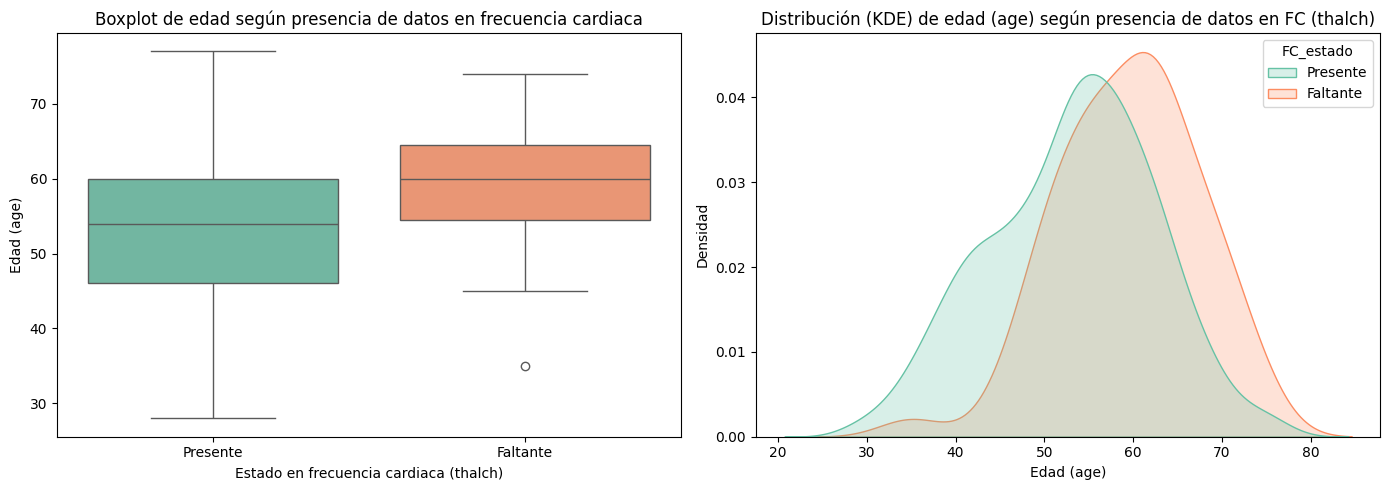

In [176]:
# ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable?
# Analisis para las columnas:#Numéricas: age, chol

# 1. Crear una columna auxiliar indicadora (máscara binaria) de datos faltantes en thalch
cardio_df['FC_estado'] = cardio_df['thalch'].isna().map({True: 'Faltante', False: 'Presente'})

# 2. Configurar la figura con subgráficos (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Gráfico 1: Boxplot Comparativo ---
sns.boxplot(data=cardio_df, x='FC_estado', y='age', hue='FC_estado', ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Boxplot de edad según presencia de datos en frecuencia cardiaca')
axes[0].set_xlabel('Estado en frecuencia cardiaca (thalch)')
axes[0].set_ylabel('Edad (age)')

# --- Gráfico 2: Diagrama de Densidad (KDE) ---
sns.kdeplot(data=cardio_df, x='age', hue='FC_estado', common_norm=False, fill=True, ax=axes[1], palette='Set2')
axes[1].set_title('Distribución (KDE) de edad (age) según presencia de datos en FC (thalch)')
axes[1].set_xlabel('Edad (age)')
axes[1].set_ylabel('Densidad')

plt.tight_layout()
plt.show()

A nivel gráfico, la frecuencia cardiaca FC (`thalch`) si tiene una relación con la   variable edad (`age`), este ultimo muestra un desplazamiento sistemático que permite diferenciar los valores cuando hay ausencia o presencia del dato de la frecuencia cardiaca FC (`thalch`). Los desplazamiento de las medianas y cajas en el boxplot, la caja y la línea de la mediana correspondientes al grupo Faltante (en color naranja) están claramente ubicadas en un rango de edad más alto en comparación con el grupo Presente (en color verde). La mediana del grupo con datos faltantes ronda los 60 años, mientras que en el grupo con datos presentes se sitúa alrededor de los 54 años. De otro lado, en el gráfico de la derecha confirma este desplazamiento. La curva de densidad del grupo Faltante (naranja) se desplaza visiblemente hacia la derecha (edades mayores, con un pico de concentración concentrado entre los 60 y 65 años), lo que indica que los datos faltantes en thalch no se distribuyen al azar respecto a la edad, sino que afectan de manera desproporcionada a pacientes de mayor edad Clínicamente esto es coherente y tiene sentido:  en pacientes mayores, los médicos a menudo omiten o deciden no realizar pruebas de esfuerzo ergométrico intensivas debido al riesgo cardiovascular elevado o a limitaciones físicas asociadas a la edad avanzada, lo que genera sistemáticamente ese patrón de valores nulos en thalch.

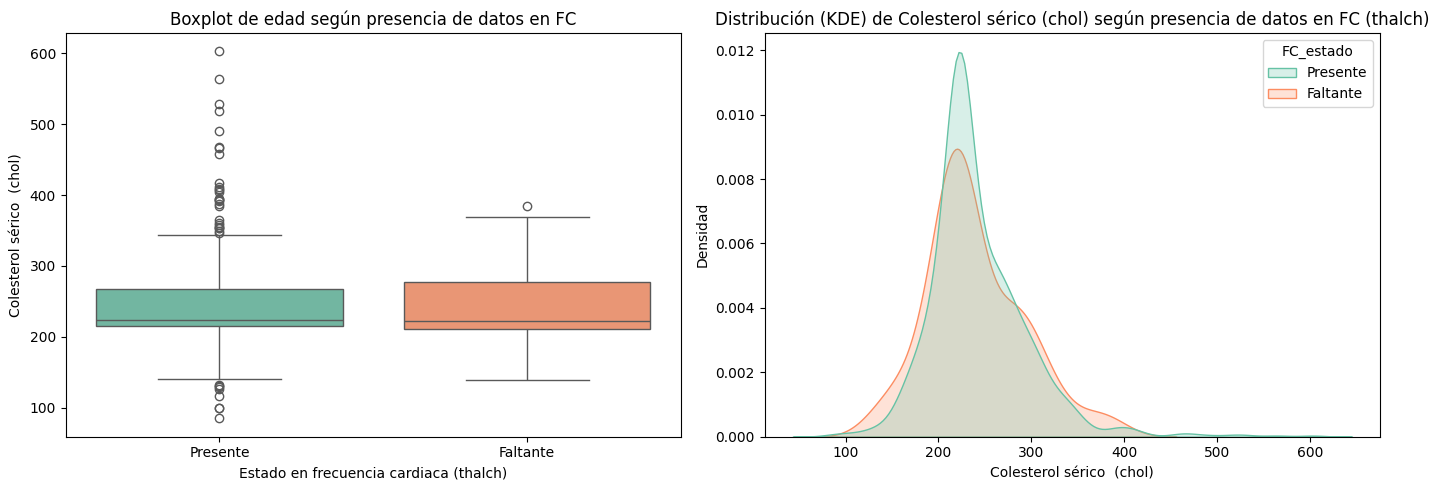

In [177]:
# ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable?
# Analisis para la columna:Numérica:  chol

# 1. Crear una columna auxiliar indicadora (máscara binaria) de datos faltantes en thalch
cardio_df['FC_estado'] = cardio_df['thalch'].isna().map({True: 'Faltante', False: 'Presente'})

# 2. Configurar la figura con subgráficos (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Gráfico 1: Boxplot Comparativo ---
sns.boxplot(data=cardio_df, x='FC_estado', y='chol', hue='FC_estado', ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Boxplot de edad según presencia de datos en FC')
axes[0].set_xlabel('Estado en frecuencia cardiaca (thalch)')
axes[0].set_ylabel('Colesterol sérico  (chol)')

# --- Gráfico 2: Diagrama de Densidad (KDE) ---
sns.kdeplot(data=cardio_df, x='chol', hue='FC_estado', common_norm=False, fill=True, ax=axes[1], palette='Set2')
axes[1].set_title('Distribución (KDE) de Colesterol sérico (chol) según presencia de datos en FC (thalch)')
axes[1].set_xlabel('Colesterol sérico  (chol)')
axes[1].set_ylabel('Densidad')

plt.tight_layout()
plt.show()

A nivel gráfico, la frecuencia cardiaca FC (`thalch`) No tiene una relación con la  otra variable colesterol (`chol`), este ultimo no muestra un desplazamiento sistemático que permita asociar directamente sus valores habituales con la ausencia o presencia del dato de la frecuencia cardiaca FC (`thalch`), más allá de que los casos extremos con colesterol muy alto se concentran en el grupo con datos completos. Por lo tanto, visualmente se comporta de manera muy homogénea entre ambos grupos.

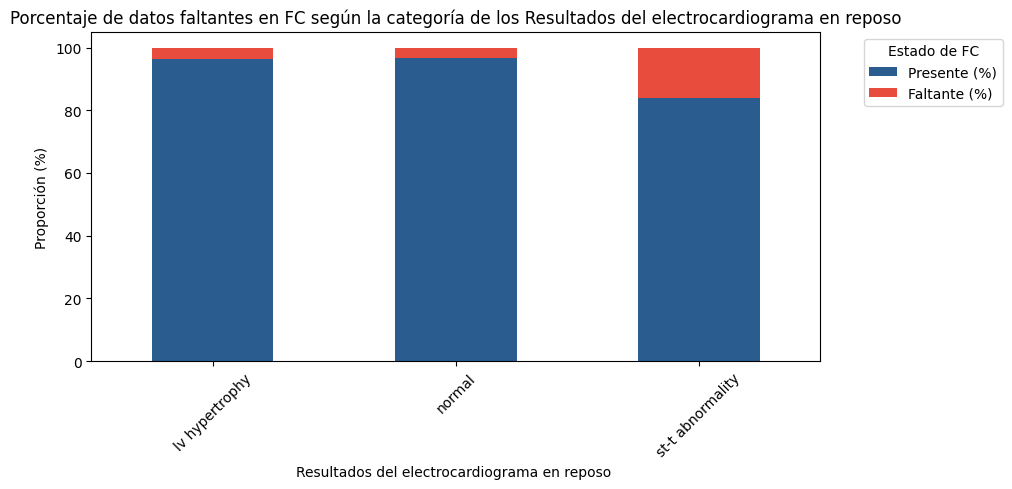

In [178]:
# ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable?
# Analisis para la columna:Categóricas: restecg, cp

# 1. Crear tabla de contingencia con frecuencias relativas (normalizada por filas)
tabla_porcentajes = pd.crosstab(
    cardio_df['restecg'],
    cardio_df['thalch'].isna(),
    normalize='index'
) * 100

# Renombrar columnas para mayor claridad
tabla_porcentajes.columns = ['Presente (%)', 'Faltante (%)']

# 2. Graficar diagrama de barras apiladas
tabla_porcentajes.plot(kind='bar', stacked=True, figsize=(10, 5), color=['#2b5c8f', '#e74c3c'])

plt.title('Porcentaje de datos faltantes en FC según la categoría de los Resultados del electrocardiograma en reposo')
plt.xlabel('Resultados del electrocardiograma en reposo ')
plt.ylabel('Proporción (%)')
plt.legend(title='Estado de FC', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

El gráfico de barras apiladas muestra, para la columna (`restecg`), para las categorías lv hypertrophy y normal, la proporción de datos faltantes (en color naranja) es  baja. En contraste, en la categoría st-t abnormality, la proporción de datos faltantes en la frecuencia cardíaca aumenta de manera muy notable. por lo anterior, se puede concluir que existe una relación altamente significativa y sistemática. Los datos faltantes en la columna (`restecg`) no ocurren al azar en esta variable, sino que se concentran de forma desproporcionada en los pacientes que presentan anomalías en el segmento st-t abnormality en su electrocardiograma de reposo.

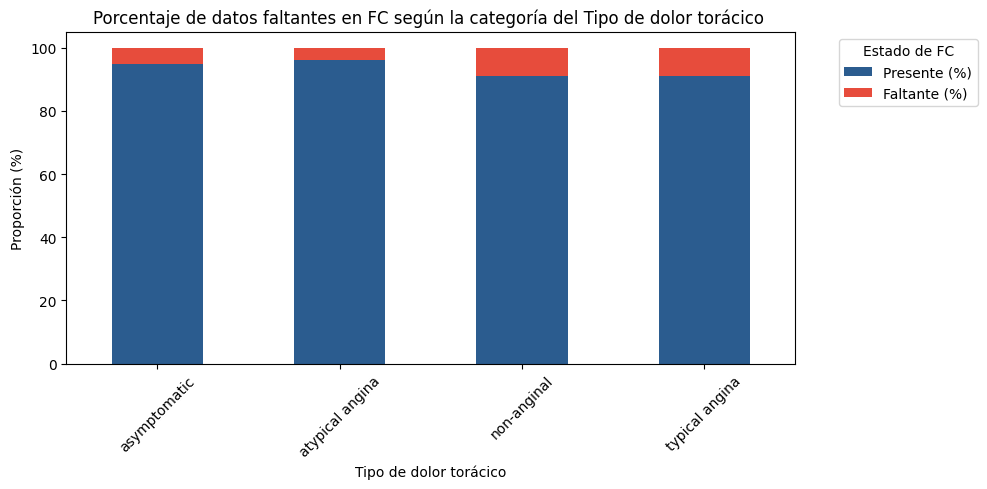

In [179]:
# ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable?
# Analisis para la columna:Categóricas: cp

# 1. Crear tabla de contingencia con frecuencias relativas (normalizada por filas)
tabla_porcentajes = pd.crosstab(
    cardio_df['cp'],
    cardio_df['thalch'].isna(),
    normalize='index'
) * 100

# Renombrar columnas para mayor claridad
tabla_porcentajes.columns = ['Presente (%)', 'Faltante (%)']

# 2. Graficar diagrama de barras apiladas
tabla_porcentajes.plot(kind='bar', stacked=True, figsize=(10, 5), color=['#2b5c8f', '#e74c3c'])

plt.title('Porcentaje de datos faltantes en FC según la categoría del Tipo de dolor torácico ')
plt.xlabel('Tipo de dolor torácico')
plt.ylabel('Proporción (%)')
plt.legend(title='Estado de FC', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

El gráfico de barras apiladas muestra, para la columna (`cp`), la proporción de datos faltantes (en color naranja) es  baja para todas las categorías, por lo que se puede concluir que no existe una relación altamente significativa y sistemática. Los datos faltantes en la columna (`cp`) ocurren al azar en esta variable. contrario a la intuicion medica no existe relación entre el dolor y la frecuencua cardiaca, la distribución de valores faltantes en la frecuencia cardíaca es independiente del tipo de dolor torácico (`cp`) reportado.

In [180]:

#Categóricas: restecg, cp
# crear indicador de faltantes
cardio_df['thalch_missing'] = cardio_df['thalch'].isnull().map(
    {True: 'Con Faltante (NaN)', False: 'Sin Faltante (Con Dato)'}
)

# 2. Pruebas de hipótesis para Numéricas
for col in ['age', 'chol']:
    grp_sin = cardio_df[cardio_df['thalch_missing'] == 'Sin Faltante (Con Dato)'][col].dropna()
    grp_con = cardio_df[cardio_df['thalch_missing'] == 'Con Faltante (NaN)'][col].dropna()
    stat, p_val = stats.ttest_ind(grp_sin, grp_con, equal_var=False)
    print(f"Variable {col} -> t-stat: {stat:.4f}, p-valor: {p_val:.4e}")

# 3. Pruebas de hipótesis para Categóricas
for col in ['restecg', 'cp']:
    contingency = pd.crosstab(cardio_df[col], cardio_df['thalch_missing'])
    chi2, p_val, dof, _ = stats.chi2_contingency(contingency)
    print(f"Variable {col} -> Chi2: {chi2:.4f}, p-valor: {p_val:.4e}")

Variable age -> t-stat: -5.6400, p-valor: 4.1159e-07
Variable chol -> t-stat: 0.3731, p-valor: 7.1047e-01
Variable restecg -> Chi2: 41.1717, p-valor: 1.1473e-09
Variable cp -> Chi2: 5.2527, p-valor: 1.5420e-01


Corroborando lo anterior con el analisis de pruebas de hipotesis se puede encontrar que existen dos variables con relación sistemática o dependencia: edad (`age`) y los resultados de los electrocardiogramas (`restecg`) las cuales presentan p-valores extremadamente bajos ($p < 0.001$), lo que demuestra que no existe independencia respecto a los datos faltantes en frecuencia cardiaca (`thalch`). Esto significa que la omisión de la prueba de esfuerzo no ocurre al azar: afecta de manera desproporcionada y sistemática a pacientes de mayor edad y a aquellos que presentan anomalías previas en el electrocardiograma en reposo (específicamente alteraciones en el segmento ST-T).

De otro lado existen dos variables independientes o sin relación: Colestero serico (`chol`) y Tipo de Dolor toracico (`cp`) las cuales muestran p-valores superiores a 0.05, que indica  que no existe una asociación estadísticamente significativa con la ausencia de datos en en frecuencia cardiaca (`thalch`).Los niveles de colesterol sérico y el tipo de dolor torácico manifestado por el paciente no condicionan ni explican por sí solos que falte el registro de la frecuencia cardíaca máxima.Conclusión General del AnálisisLos valores faltantes en thalch responden a un patrón de datos faltantes aleatorios condicionados (MAR - Missing at Random). Su ausencia está guiada principalmente por el perfil de riesgo electrocardiográfico basal (restecg) y etario (age) del paciente, lo cual concuerda con criterios clínicos donde a ciertos grupos de pacientes (como adultos mayores o con trazados electrocardiográficos alterados) no se les prioriza o somete a pruebas de esfuerzo ergométrico.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

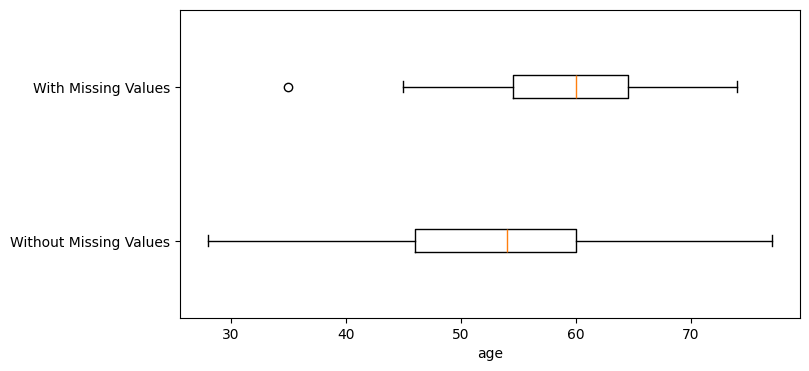

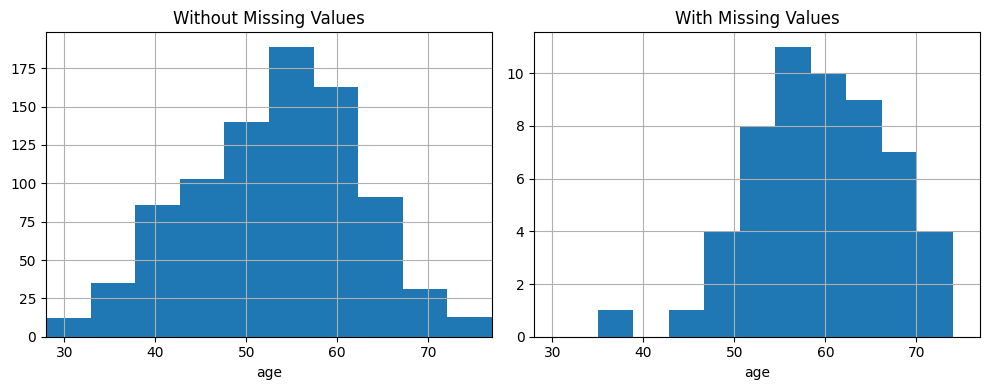

p-value of t-test: 1.5041244185890902e-06


In [181]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import ttest_ind


def Diagnose_MV_Numerical(cardio_df, str_att_name, BM_MV):
  MV_labels = {True: 'With Missing Values', False: 'Without Missing Values'}

  labels = []
  box_sr = pd.Series(index=BM_MV.unique(), dtype=object)
  for poss in BM_MV.unique():
    BM = BM_MV == poss
    box_sr[poss] = cardio_df[BM][str_att_name].dropna()
    labels.append(MV_labels[poss])

  # 1. Gráfico de Boxplot
  plt.figure(figsize=(8, 4))
  plt.boxplot(box_sr, vert=False)
  plt.yticks([1, 2], labels)
  plt.xlabel(str_att_name)
  plt.show()

  # 2. Gráficos de Histogramas
  plt.figure(figsize=(10, 4))
  att_range = (cardio_df[str_att_name].min(), cardio_df[str_att_name].max())

  for i, poss in enumerate(BM_MV.unique()):
    plt.subplot(1, 2, i + 1)
    BM = BM_MV == poss
    cardio_df[BM][str_att_name].hist()
    plt.xlim(att_range)  # Corrección aplicada aquí
    plt.xlabel(str_att_name)
    plt.title(MV_labels[poss])

  plt.tight_layout()
  plt.show()

  # 3. Prueba t de Student para evaluar si es MCAR o MAR
  group_1_data = cardio_df[BM_MV][str_att_name].dropna()
  group_2_data = cardio_df[~BM_MV][str_att_name].dropna()

  p_value = ttest_ind(group_1_data, group_2_data).pvalue

  print('p-value of t-test: {}'.format(p_value))


# === EJECUCIÓN (Ejemplo de llamada) ===
# Definir la máscara para thalch
BM_MV_thalch = cardio_df['thalch'].isnull()

# Ejecutar la función
Diagnose_MV_Numerical(cardio_df, 'age', BM_MV_thalch)

A partir de los gráficos presentados en ambas imágenes, el mecanismo de datos faltantes para la frecuencia cardíaca se clasifica como MAR (Missing at Random).
De acuerdo con el análisis del Boxplot, y aplicando una diferencia en las Medias y Medianas:En la ategoría "Without Missing Values" (datos presentes), la mediana de edad se sitúa alrededor de los 54 años, con un rango intercuartílico (caja) que abarca de los 46 a los 60 años. En la categoría "With Missing Values" (datos faltantes), la mediana sube notablemente a 60 años, y la caja se desplaza hacia la derecha, abarcando de los 55 a los 65 años. En conclusión del Boxplot: La distribución de la edad no es idéntica en ambos grupos; los datos faltantes se concentran en pacientes de mayor edad. De otro lado en el análisis de los Histogramas y a partir de la diferencia en las distribuciones, se encuentra que el histograma "Without Missing Values" muestra una distribución normal centrada entre los 50 y 55 años, con presencia importante de pacientes jóvenes (entre 30 y 45 años). mientras que el histograma "With Missing Values" muestra que la gran masa de datos faltantes se acumula a partir de los 55 a 70 años, siendo casi inexistentes los nulos en pacientes menores de 45 años.

En conclusión, si la ausencia de datos fuera MCAR (Missing Completely at Random), las distribuciones (tanto en el boxplot como en los histogramas) deberían ser prácticamente idénticas en forma, mediana y dispersión, indicando que la probabilidad de que un valor falte es completamente independiente de la edad (age). al contrario como es MAR (Missing at Random), la presencia o ausencia del valor faltante depende directamente de una variable observada en el dataset (age). Dado que los datos faltantes ocurren de manera sistemática y desproporcionada en adultos mayores, se confirma el patrón MAR.

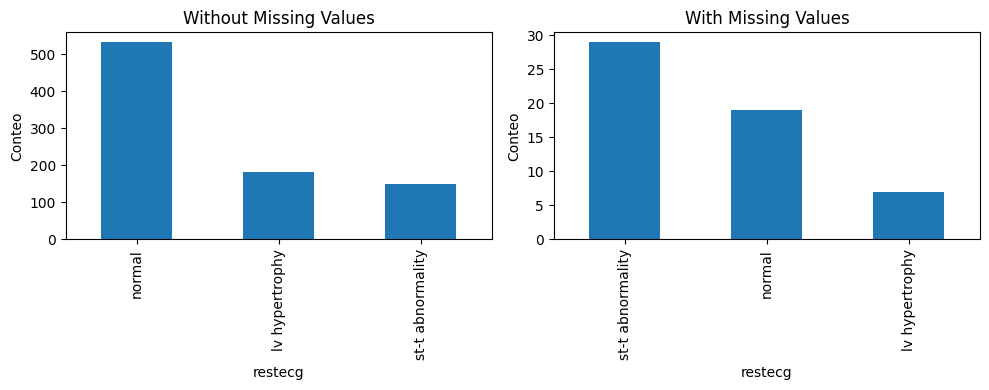

p-value of Chi_squared test: 1.1472889573985467e-09


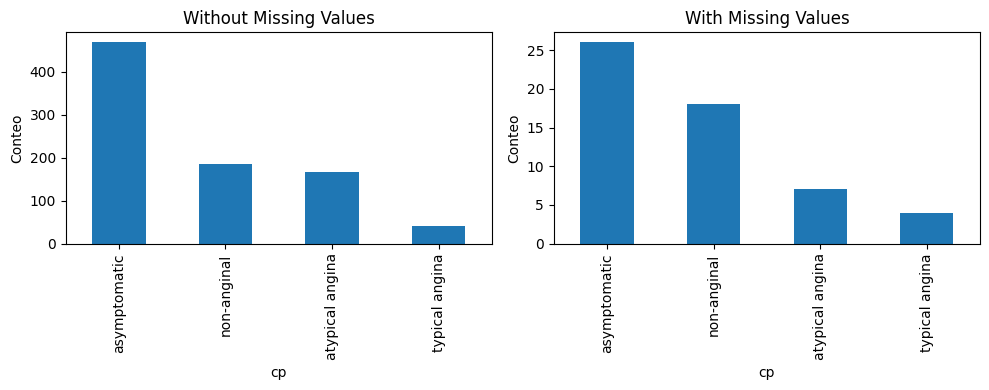

p-value of Chi_squared test: 0.15420097177251701


In [182]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import chi2_contingency


def Diagnose_MV_Categorical(cardio_df, str_att_name, BM_MV):
  MV_labels = {True: 'With Missing Values', False: 'Without Missing Values'}

  plt.figure(figsize=(10, 4))
  for i, poss in enumerate(BM_MV.unique()):
    plt.subplot(1, 2, i + 1)
    BM = BM_MV == poss

    # 1. Corregido: se usa 'cardio_df' en lugar de 'df'
    cardio_df[BM][str_att_name].value_counts().plot.bar()
    plt.title(MV_labels[poss])
    plt.xlabel(str_att_name)
    plt.ylabel('Conteo')

  plt.tight_layout()
  plt.show()

  # 2. Corregido: tabla cruzada con 'cardio_df'
  contingency_table = pd.crosstab(BM_MV, cardio_df[str_att_name])
  p_value = chi2_contingency(contingency_table)[1]

  print('p-value of Chi_squared test: {}'.format(p_value))


# 1. Crear la máscara booleana de valores faltantes para thalch
BM_MV_thalch = cardio_df['thalch'].isnull()

# 2. Llamar a la función para 'restecg'
Diagnose_MV_Categorical(cardio_df, 'restecg', BM_MV_thalch)

# 3. Llamar a la función para 'cp'
Diagnose_MV_Categorical(cardio_df, 'cp', BM_MV_thalch)

Apoyándote en las imágenes de barras, se puede justificar que para variables como `restecg`, el mecanismo es MAR porque la estructura visual cambia sistemáticamente entre los pacientes con y sin datos, probando que la falta de registro en `thalch` está condicionada por el perfil clínico del paciente. Es sdecir para las variables categóricas restecg y cp, y su relación con los valores faltantes en thalch, se pueden identificar visualmente las diferencias clave en las distribuciones. Para la Variable `restecg` (Primer gráfico)Without Missing Values (Datos presentes): La categoría normal es claramente la más dominante por amplio margen, seguida por lv hypertrophy y st-t abnormality en menor medida.With Missing Values (Datos faltantes): El orden de las categorías cambia drásticamente. La categoría st-t abnormality pasa a ser la más frecuente en el grupo con nulos, seguida por normal y dejando a lv hypertrophy en el último lugar.Conclusión: Las proporciones de las categorías cambian de forma evidente entre ambos gráficos, lo que refleja visualmente la fuerte asociación y dependencia que demostró la prueba estadística de Chi-cuadrado ($p$-valor muy bajo). Esto apunta directamente a un mecanismo de tipo MAR (Missing at Random).

De otro lado la Variable `cp` (Segundo gráfico) tanto el Without Missing Values y With Missing Values la categoría asymptomatic es la más alta por mucho, seguida por non-anginal, atypical angina y typical angina en exactamente el mismo orden de frecuencia descendente. Conclusión: Las distribuciones relativas de las barras son casi idénticas en ambas condiciones (la forma visual de los gráficos de barras se mantiene muy estable). Esto indica visualmente que la proporción de pacientes en cada categoría de dolor torácico no se altera de manera drástica cuando falta el dato de thalch, lo cual es coherente con un resultado no significativo ($p > 0.05$).

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [183]:
# lista de variables a imputar según tu requerimiento
cols_to_impute = ['thalch', 'trestbps', 'exang', 'oldpeak', 'chol', 'fbs']

# Ciclo para  cada variable e imputar por grupos de 'restecg' según su tipo de dato
for col in cols_to_impute:
  if col in cardio_df.columns:
    # Si la variable es numérica (ej: thalch, trestbps, oldpeak, chol)
    if pd.api.types.is_numeric_dtype(cardio_df[col]):
      cardio_df[col] = cardio_df.groupby('restecg')[col].transform(
          lambda x: x.fillna(x.median())
      )
    # para las variables  categórica o de texto (ej: exang, fbs)
    else:
      cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(
          x.mode()[0] if not x.mode().empty else 'Desconocido'
      ))

# Verificar que ya no queden valores nulos en estas columnas
print('Valores nulos después de la imputación por grupos:')
print(cardio_df[cols_to_impute].isnull().sum())


Valores nulos después de la imputación por grupos:
thalch      0
trestbps    0
exang       0
oldpeak     0
chol        0
fbs         0
dtype: int64


/tmp/ipykernel_1633/899155016.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(
/tmp/ipykernel_1633/899155016.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(


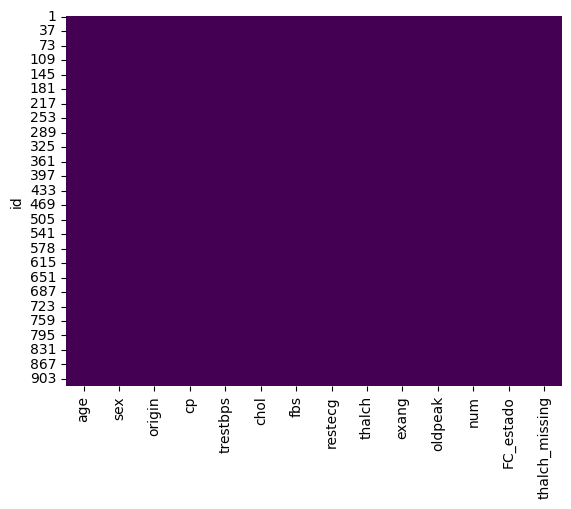

In [184]:
#Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
sns.heatmap(cardio_df.isna(), cbar=False, cmap='viridis')
plt.show()

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [185]:
import pandas as pd
from sklearn.impute import SimpleImputer

# Separar las columnas según su naturaleza
cols_numericas = ['trestbps', 'chol', 'oldpeak', 'thalch']
cols_categoricas = ['exang', 'fbs']

#  Imputar para variables numéricas usando la MEDIANA
imputer_num = SimpleImputer(strategy='median')
if cols_numericas:
    cardio_df[cols_numericas] = imputer_num.fit_transform(cardio_df[cols_numericas])

# Imputación para variables categóricas (convertimos a entero/objeto temporalmente si son bool)
for col in cols_categoricas:
    if cardio_df[col].dtype == bool:
        cardio_df[col] = cardio_df[col].astype(float) # o int

imputer_cat = SimpleImputer(strategy='most_frequent')
if cols_categoricas:
    cardio_df[cols_categoricas] = imputer_cat.fit_transform(cardio_df[cols_categoricas])


# Verificación final de valores nulos
print('Conteo total de nulos tras la imputación global:')
print(cardio_df.isnull().sum().sum())

Conteo total de nulos tras la imputación global:
0


Para realizar la imputación de valores faltantes utilizando estadísticas globales sobre toda la columna con la clase SimpleImputer de scikit-learn, primero debemos definir qué estrategia (mean, median o most_frequent) aplicar a cada tipo de variable.Para las Variables Numéricas Continuas / Métricas (ej. trestbps, chol, oldpeak, thalch): se recomienda la Mediana, esto en tanto, las variables médicas y fisiológicas a menudo presentan valores atípicos (outliers) extremos (por ejemplo, picos inusitados de colesterol o presión arterial). La mediana es una medida robusta que no se ve arrastrada por estos valores extremos, reflejando de manera más fiel el comportamiento central de los datos sin sesgar la distribución.

De otro lado, para las variables categóricas, Binarias, de texto (ej. exang, fbs, restecg, etc.): la estrategia recomendada es usar el valor mas frecuente o moda. La justificación es que en variables de tipo cualitativo o binario no se pueden promediar valores. Utilizar la categoría más repetida permite rellenar los datos faltantes manteniendo la proporción natural de la clase predominante sin alterar artificialmente la estructura categórica.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

/tmp/ipykernel_1633/125530381.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot_dict = plt.boxplot(


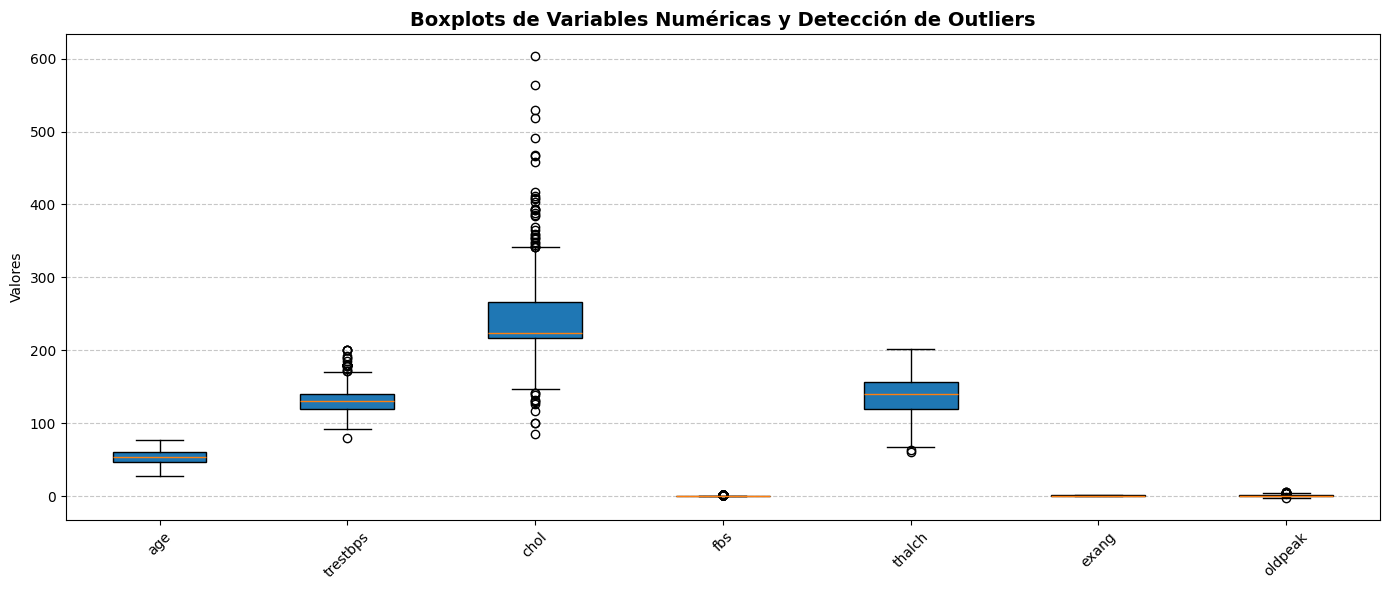

In [186]:
# Seleccionar  las columnas de tipo numérico del DataFrame
cols_numericas = cardio_df.select_dtypes(
    include=['int64', 'float64']
).columns

# Configuración de la figura para mostrar los boxplots
plt.figure(figsize=(14, 6))

# Al usar return_type='dict' o plt.boxplot directamente, podemos capturar los elementos gráficos
# Convertimos el DataFrame a lista por columnas para plotear
data_to_plot = [cardio_df[col].dropna() for col in cols_numericas]

# Generar el boxplot y capturar el diccionario de componentes gráficos
boxplot_dict = plt.boxplot(
    data_to_plot, labels=cols_numericas, patch_artist=True
)

plt.title(
    'Boxplots de Variables Numéricas y Detección de Outliers',
    fontsize=14,
    fontweight='bold',
)
plt.ylabel('Valores')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()



Apartir de los BoxPlots se encuentran los siguientes valores atípicos:



*   Variable 'age': No se deectan outliers gráficos.
*   Variable 'trestbps': 27 outliers encontrados. Valores: [ 80. 172. 180. 200. 174. 178. 192. 180. 178. 180. 190. 180. 180. 180. 180. 200. 180. 180. 180. 200. 185. 200. 180. 178. 172. 180. 190.]
*   Variable 'chol': 44 outliers encontrados. Valores: [141. 126. 131. 132. 129. 100.  85. 117. 100. 142. 139. 354. 353. 417.  360. 407. 564. 394. 409. 342. 358. 412. 468. 365. 344. 394. 347. 466.  529. 392. 355. 603. 342. 404. 518. 388. 491. 342. 393. 458. 384. 349.  369. 385.]

* Variable 'fbs': 138 outliers encontrados. Valores: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.  1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.  1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.  1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.  1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.  1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

* Variable 'thalch': 2 outliers encontrados. Valores: [60. 63.]

* Variable 'exang': No se detectaron outliers gráficos.
* Variable 'oldpeak': 16 outliers encontrados. Valores: [-2.6  6.2  4.   5.6 4.   4.2  4.2  3.8  4.4  4.   4.   5.   4.   4.  4.   4. ]

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [187]:
import pandas as pd

# calcular el Cuartil 1 (25%) y Cuartil 3 (75%) de la variable trestbps
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)

# calcular el Rango Intercuartílico (IQR)
IQR = Q3 - Q1

# definir los límites inferior y superior (factor estándar de 1.5)
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f'Q1 (25%): {Q1}')
print(f'Q3 (75%): {Q3}')
print(f'IQR: {IQR}')
print(f'Límite Inferior: {limite_inferior}')
print(f'Límite Superior: {limite_superior}')

# Filtrar y extraer los valores atípicos (fuera de los límites)
outliers_trestbps = cardio_df[
    (cardio_df['trestbps'] < limite_inferior)
    | (cardio_df['trestbps'] > limite_superior)
]

print(f'\nTotal de valores atípicos encontrados: {len(outliers_trestbps)}')
outliers_trestbps['trestbps']

Q1 (25%): 120.0
Q3 (75%): 140.0
IQR: 20.0
Límite Inferior: 90.0
Límite Superior: 170.0

Total de valores atípicos encontrados: 27


,trestbps
id,
15,172.0
84,180.0
127,200.0
173,174.0
184,178.0
189,192.0
202,180.0
214,178.0
232,180.0


Si coninciden los valores, en ambos casos da 27.
Variable `trestbps`: 27 outliers encontrados. Valores: [ 80. 172. 180. 200. 174. 178. 192. 180. 178. 180. 190. 180. 180. 180. 180. 200. 180. 180. 180. 200. 185. 200. 180. 178. 172. 180. 190.]

10. Elimina los valores atípicos identificados de la variable `trestbps`.\
* Dibuja el boxplot final para visualizar la distribución depurada.

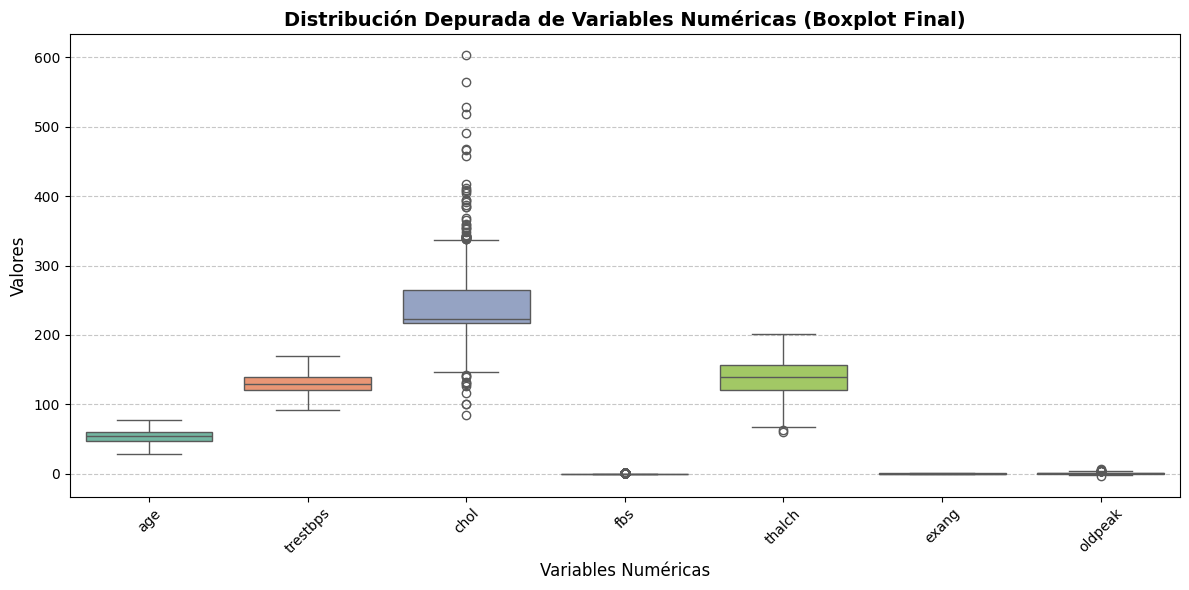

In [188]:
# Calcular Q1, Q3 e IQR para trestbps
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar el DataFrame conservando ÚNICAMENTE los valores que están DENTRO de los límites permitidos
cardio_df = cardio_df[
    (cardio_df['trestbps'] >= limite_inferior) &
    (cardio_df['trestbps'] <= limite_superior)
]

# Restablecer los índices del DataFrame después de eliminar filas
cardio_df = cardio_df.reset_index(drop=True)

#BoxPlot para visualizar la distribucion depurada
# Configurar el tamaño de la figura
plt.figure(figsize=(12, 6))

# generar el boxplot utilizando el DataFrame ya depurado (cardio_df)
sns.boxplot(data=cardio_df.select_dtypes(include=['int64', 'float64']), palette='Set2')

# Personalizar la gráfica
plt.title('Distribución Depurada de Variables Numéricas (Boxplot Final)', fontsize=14, fontweight='bold')
plt.xlabel('Variables Numéricas', fontsize=12)
plt.ylabel('Valores', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

#Ajustes de diseño y mostrar
plt.tight_layout()
plt.savefig('boxplot_final_depurado.png', dpi=300)
plt.show()


Como se aprecia la variable `trestbps` no presenta datos atipicos

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---